# Customer Churn: Classification, Risk Scoring and Segmentation

**Question:** which telecom customers are likely to leave, and what do the groups at risk look like?

The data is **simulated**: 7,043 customers with the same 21 columns as the well-known IBM Telco Customer Churn sample, generated by `src/generate_data.py` from a known churn model (so every finding can be checked against the truth). Three complementary models:

1. **Logistic regression (classification):** churn yes/no, evaluated with ROC-AUC, precision and recall.
2. **Churn probability scoring:** the same model's probabilities, checked for calibration with the Brier score.
3. **K-Means segmentation:** customer groups built from tenure and spend, profiled by churn rate.

Run top to bottom, locally or in Google Colab (the data is read straight from this GitHub repository if the local copy is missing).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             brier_score_loss, silhouette_score)
from sklearn.calibration import calibration_curve

SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
os.makedirs("../reports/figures", exist_ok=True)

## 1. Load the data

In [2]:
LOCAL_PATH = "../data/telco_customer_churn.csv"
REMOTE_PATH = ("https://raw.githubusercontent.com/mohammedelsayed741996-blip/"
               "telco-customer-churn-ml/main/data/telco_customer_churn.csv")
df = pd.read_csv(LOCAL_PATH if os.path.exists(LOCAL_PATH) else REMOTE_PATH)
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

7,043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,2204-DUMPP,Female,0,Yes,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Credit card (automatic),25.58,26.15,No
1,7408-AMDKY,Female,0,Yes,Yes,61,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,24.57,1477.95,No
2,5929-BODTY,Male,0,No,No,30,Yes,Yes,Fiber optic,Yes,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,103.61,2997.52,No
3,9814-QWJDN,Female,0,No,No,18,No,No phone service,DSL,No,No,Yes,No,Yes,No,Month-to-month,Yes,Electronic check,59.80,1138.12,Yes
4,4993-RZHWD,Male,0,No,No,19,Yes,No,DSL,No,No,Yes,Yes,Yes,Yes,Month-to-month,No,Electronic check,76.58,1514.22,Yes


## 2. Data quality

`TotalCharges` is stored as text. Customers with `tenure = 0` (new sign-ups, not yet billed) have a blank value. They are filled with 0, which is what a blank bill means, rather than with the column mean.

In [3]:
print("Missing values (as loaded):", int(df.isna().sum().sum()))
print("Duplicated customer IDs:", int(df["customerID"].duplicated().sum()))

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip().replace("", np.nan))
blank = df["TotalCharges"].isna()
print("Blank TotalCharges:", int(blank.sum()), "| tenure of those rows:", sorted(df.loc[blank, "tenure"].unique()))
df.loc[blank, "TotalCharges"] = 0.0

df["Churn"] = (df["Churn"] == "Yes").astype(int)
df = df.drop(columns="customerID")
print(f"Churn rate: {df['Churn'].mean():.1%}")

Missing values (as loaded): 0
Duplicated customer IDs: 0
Blank TotalCharges: 11 | tenure of those rows: [np.int64(0)]
Churn rate: 27.8%


## 3. Exploratory analysis

In [4]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
df[num_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,31.61,68.42,2169.96
std,21.00,25.00,1725.73
min,0.00,18.25,0.00
25%,14.00,56.60,758.00
50%,30.00,74.88,1775.11
75%,48.00,87.23,3336.29
max,72.00,115.70,8404.56


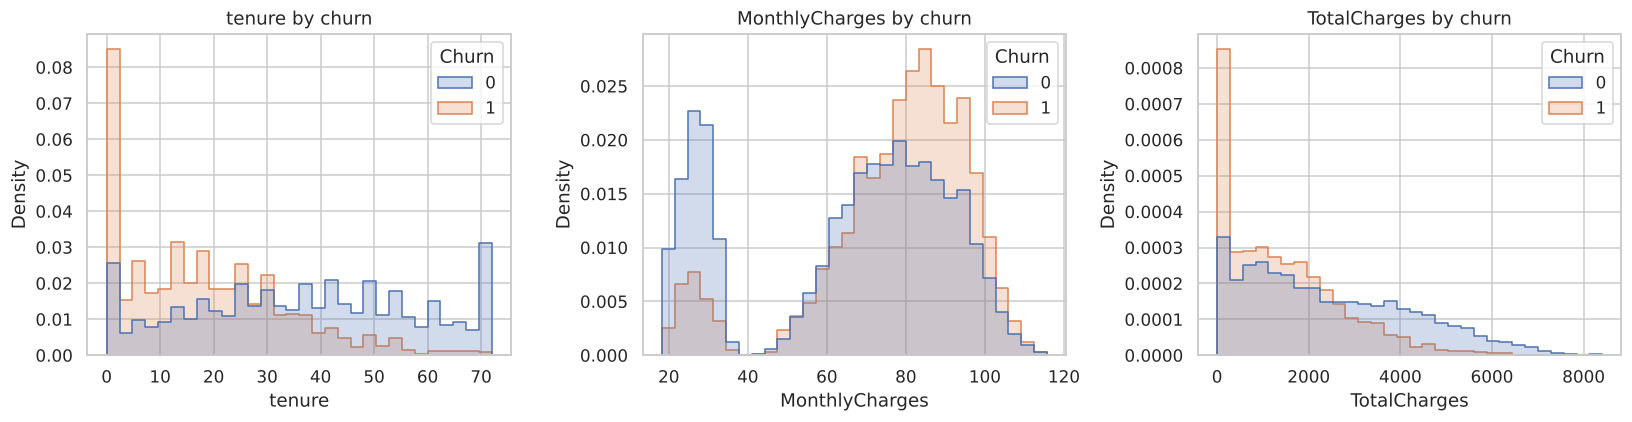

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Churn", bins=30, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.savefig("../reports/figures/numeric_distributions.png", dpi=120)

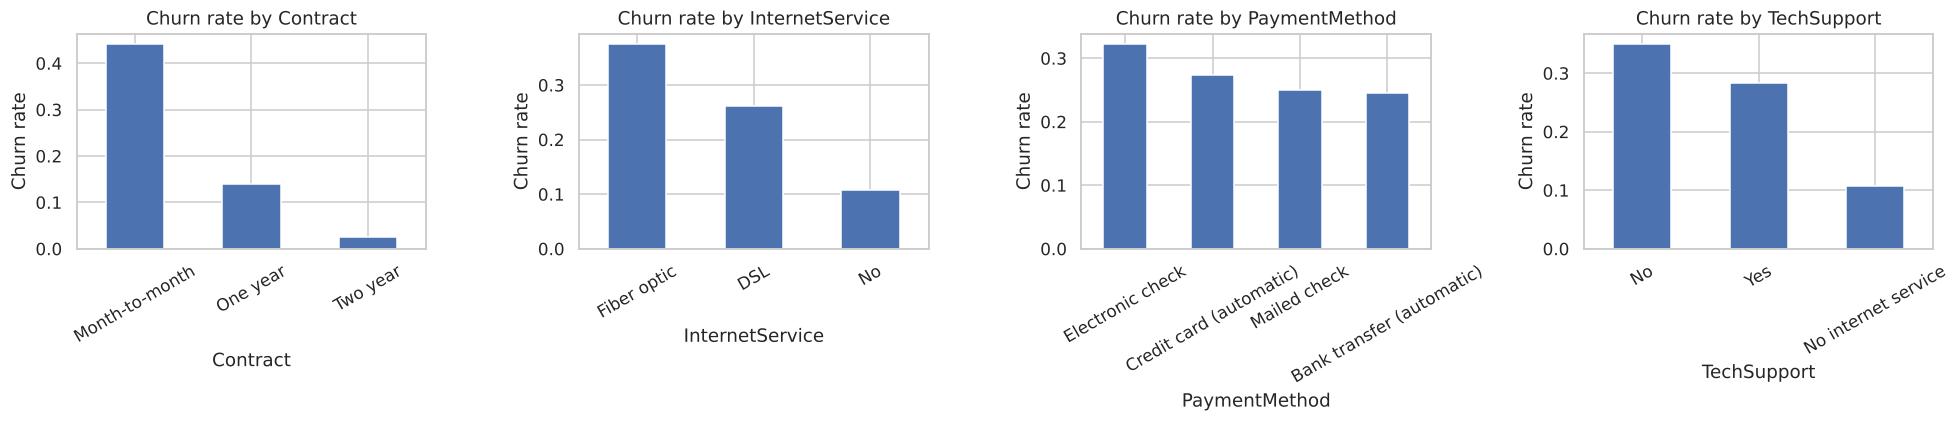

In [6]:
cat_view = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cat_view):
    rate = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    rate.plot.bar(ax=ax, color="#4C72B0")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("../reports/figures/churn_rate_by_category.png", dpi=120)

In [7]:
churn_by_contract = df.groupby("Contract")["Churn"].agg(customers="size", churn_rate="mean")
churn_by_contract["churn_rate"] = churn_by_contract["churn_rate"].round(3)
churn_by_contract

,customers,churn_rate
Contract,,
Month-to-month,3871,0.442
One year,1472,0.141
Two year,1700,0.025


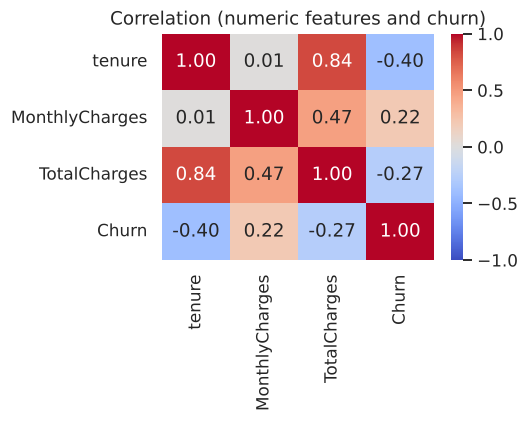

In [8]:
plt.figure(figsize=(5, 4))
sns.heatmap(df[num_cols + ["Churn"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation (numeric features and churn)")
plt.tight_layout()

## 4. Model 1: logistic regression classifier

All 19 features are used: numeric ones scaled, categorical ones one-hot encoded inside a pipeline, so the test set never influences the preprocessing. The split is stratified to keep the 26.5% churn share in both sets.

In [9]:
X = df.drop(columns="Churn")
y = df["Churn"]
cat_cols = [c for c in X.columns if c not in num_cols]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols),
])
clf = Pipeline([("prep", preprocess),
                ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))])

cv_auc = cross_val_score(clf, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc")
print(f"5-fold CV ROC-AUC on the training set: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")

clf.fit(X_train, y_train)
proba = clf.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Baseline accuracy (always 'no churn'): {baseline.score(X_test, y_test):.3f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, proba):.3f}")
print(classification_report(y_test, pred, target_names=["Stay", "Churn"], digits=3))

5-fold CV ROC-AUC on the training set: 0.838 ± 0.011
Baseline accuracy (always 'no churn'): 0.722
Test ROC-AUC: 0.842
              precision    recall  f1-score   support

        Stay      0.903     0.732     0.808      1017
       Churn      0.533     0.796     0.639       392

    accuracy                          0.749      1409
   macro avg      0.718     0.764     0.723      1409
weighted avg      0.800     0.749     0.761      1409



`class_weight="balanced"` trades some precision for recall. For churn that is usually the right trade: missing a leaving customer costs more than one extra retention call.

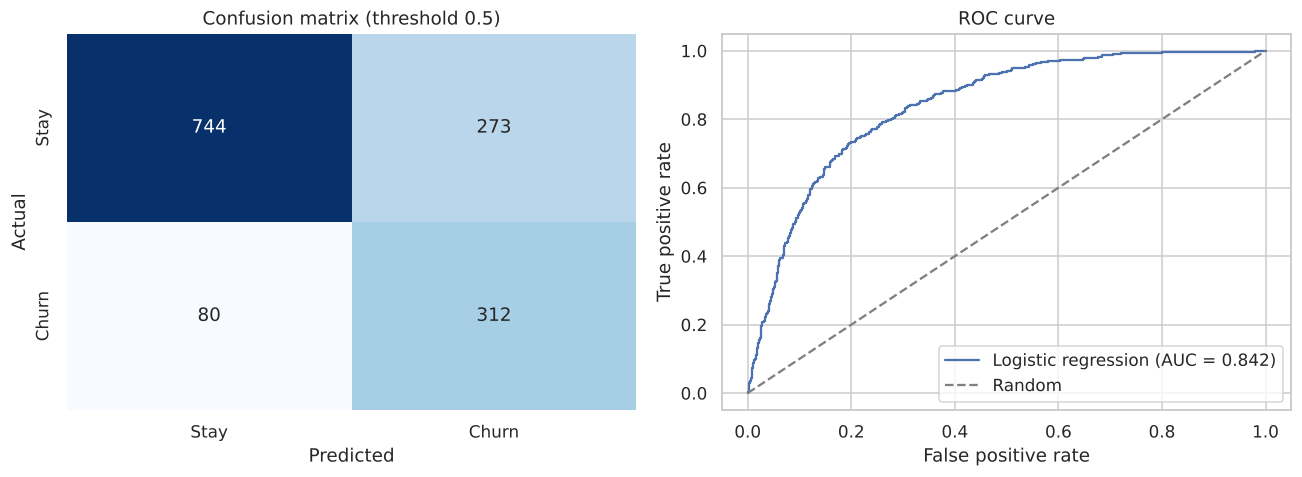

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].set_title("Confusion matrix (threshold 0.5)")
fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, label=f"Logistic regression (AUC = {roc_auc_score(y_test, proba):.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="grey", label="Random")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC curve")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.savefig("../reports/figures/confusion_matrix_roc.png", dpi=120)

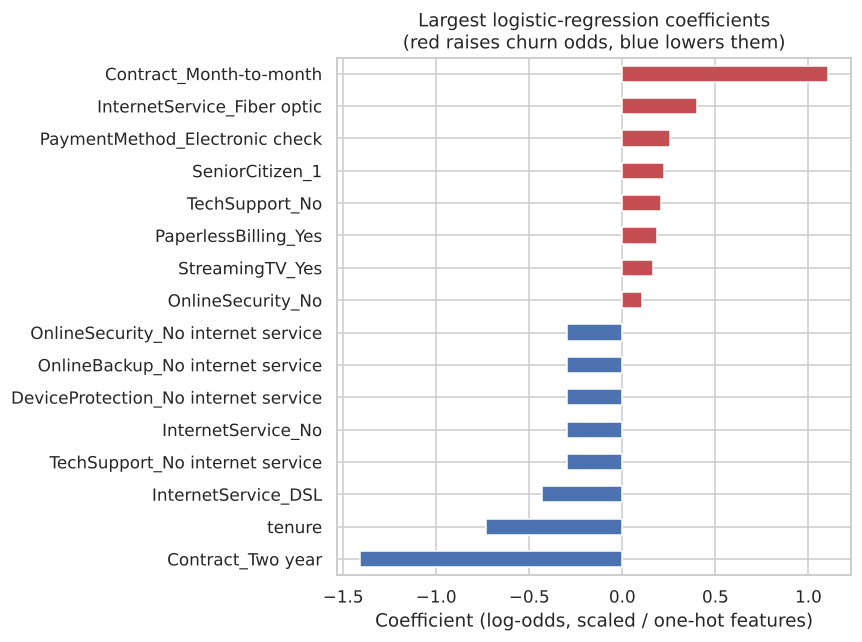

In [11]:
feature_names = clf.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(clf.named_steps["model"].coef_[0], index=[f.split("__", 1)[1] for f in feature_names])
top = pd.concat([coefs.nlargest(8), coefs.nsmallest(8)]).sort_values()
plt.figure(figsize=(8, 6))
top.plot.barh(color=np.where(top > 0, "#C44E52", "#4C72B0"))
plt.title("Largest logistic-regression coefficients\n(red raises churn odds, blue lowers them)")
plt.xlabel("Coefficient (log-odds, scaled / one-hot features)")
plt.tight_layout()
plt.savefig("../reports/figures/top_coefficients.png", dpi=120)

## 5. Model 2: churn probability scoring

Retention teams work from a ranked list, not a yes/no label. The model below is trained **without** class weights so its probabilities stay calibrated. Its quality is checked with the Brier score (mean squared error of the probabilities) and a calibration curve.

In [12]:
scorer = Pipeline([("prep", preprocess),
                   ("model", LogisticRegression(max_iter=2000, random_state=SEED))]).fit(X_train, y_train)
p = scorer.predict_proba(X_test)[:, 1]
brier = brier_score_loss(y_test, p)
brier_ref = brier_score_loss(y_test, np.full_like(p, y_train.mean()))
print(f"Brier score: {brier:.4f} (reference, predicting the base rate for everyone: {brier_ref:.4f})")
print(f"Brier skill score: {1 - brier / brier_ref:.3f}")

scored = pd.DataFrame({"churn_probability": p, "actual": y_test.values})
scored["risk_decile"] = pd.qcut(scored["churn_probability"].rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = scored.groupby("risk_decile", observed=True)["actual"].agg(customers="size", churn_rate="mean")
lift["lift_vs_average"] = (lift["churn_rate"] / y_test.mean()).round(2)
lift["churn_rate"] = lift["churn_rate"].round(3)
lift

Brier score: 0.1406 (reference, predicting the base rate for everyone: 0.2008)
Brier skill score: 0.300


,customers,churn_rate,lift_vs_average
risk_decile,,,
1,141,0.709,2.55
2,141,0.652,2.35
3,141,0.489,1.76
4,141,0.319,1.15
5,141,0.248,0.89
6,140,0.171,0.62
7,141,0.106,0.38
8,141,0.057,0.20
9,141,0.021,0.08


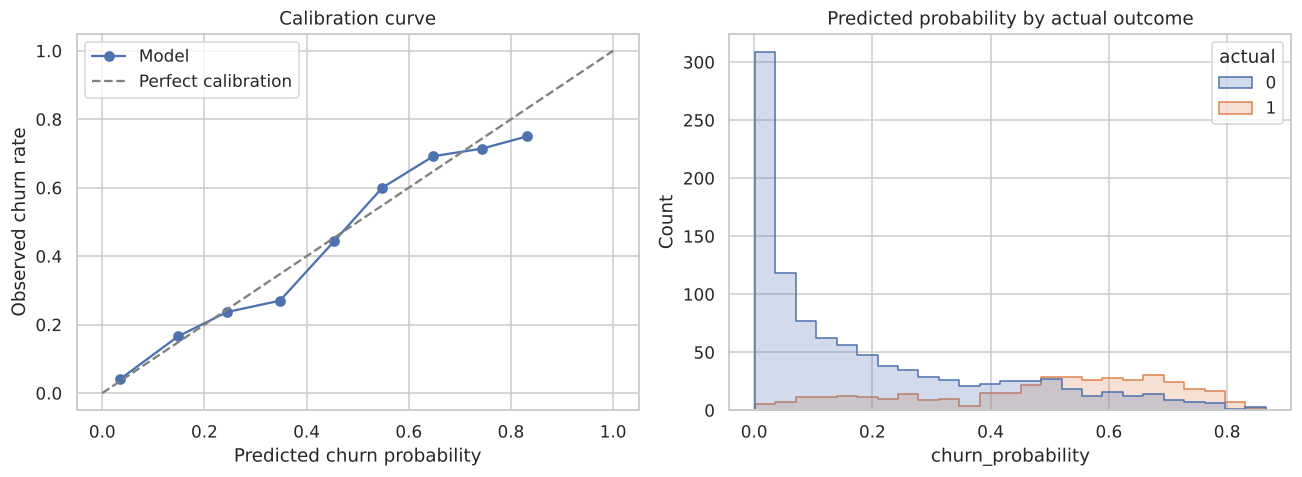

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10)
axes[0].plot(mean_pred, frac_pos, "o-", label="Model")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="Perfect calibration")
axes[0].set_xlabel("Predicted churn probability"); axes[0].set_ylabel("Observed churn rate")
axes[0].set_title("Calibration curve"); axes[0].legend()
sns.histplot(data=scored, x="churn_probability", hue="actual", bins=25, element="step", ax=axes[1])
axes[1].set_title("Predicted probability by actual outcome")
plt.tight_layout()
plt.savefig("../reports/figures/calibration_and_scores.png", dpi=120)

## 6. Model 3: K-Means customer segmentation

Segments use behaviour only (tenure, monthly and total charges), scaled. Churn is **not** an input. It is used afterwards to describe each segment. The number of clusters is the one with the highest silhouette score, checked against the elbow curve.

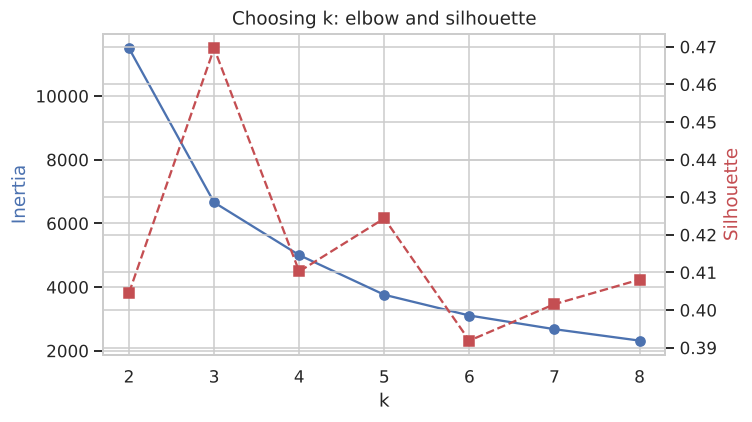

,k,inertia,silhouette
0,2,11499.0,0.405
1,3,6660.0,0.470
2,4,5005.0,0.410
3,5,3759.0,0.424
4,6,3108.0,0.392
5,7,2678.0,0.402
6,8,2319.0,0.408


In [14]:
seg_X = StandardScaler().fit_transform(df[num_cols])
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(seg_X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(seg_X, km.labels_, sample_size=3000, random_state=SEED))

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(list(ks), inertia, "o-", color="#4C72B0"); ax1.set_xlabel("k"); ax1.set_ylabel("Inertia", color="#4C72B0")
ax2 = ax1.twinx(); ax2.plot(list(ks), sil, "s--", color="#C44E52"); ax2.set_ylabel("Silhouette", color="#C44E52")
plt.title("Choosing k: elbow and silhouette")
plt.tight_layout()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 0), "silhouette": np.round(sil, 3)})

In [15]:
K = list(ks)[int(np.argmax(sil))]  # k with the best silhouette score
print("Chosen k:", K)
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(seg_X)
df["Segment"] = km.labels_
profile = df.groupby("Segment").agg(customers=("Churn", "size"), churn_rate=("Churn", "mean"),
                                    avg_tenure=("tenure", "mean"), avg_monthly=("MonthlyCharges", "mean"),
                                    month_to_month_share=("Contract", lambda s: (s == "Month-to-month").mean()))
profile = profile.sort_values("churn_rate", ascending=False).round(3)
profile

Chosen k: 3


,customers,churn_rate,avg_tenure,avg_monthly,month_to_month_share
Segment,,,,,
2,3056,0.490,15.999,79.479,0.824
1,2363,0.118,52.038,81.687,0.190
0,1624,0.113,31.257,28.288,0.557


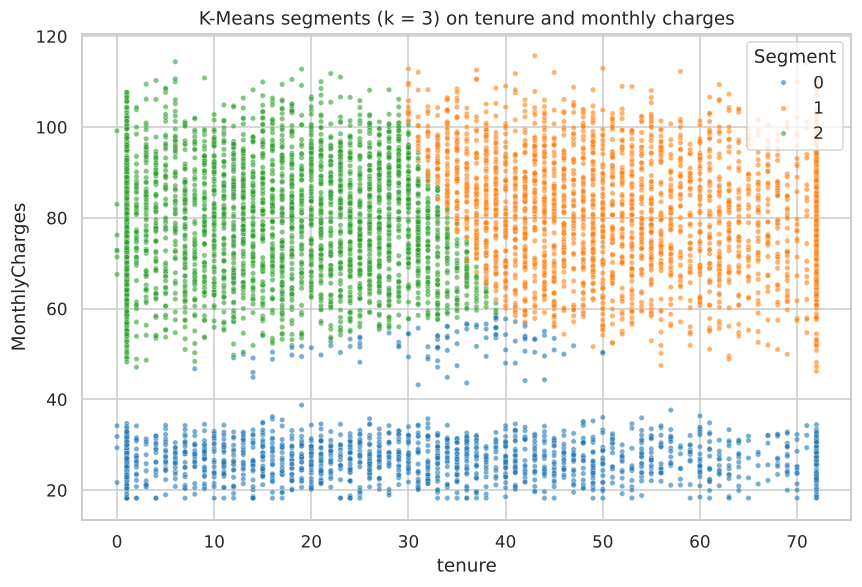

In [16]:
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=df, x="tenure", y="MonthlyCharges", hue="Segment", palette="tab10", s=12, alpha=0.6)
plt.title(f"K-Means segments (k = {K}) on tenure and monthly charges")
plt.tight_layout()
plt.savefig("../reports/figures/segments.png", dpi=120)

## 7. Results summary

In [17]:
summary = pd.DataFrame({
    "metric": ["Customers", "Churn rate", "LR test ROC-AUC", "LR 5-fold CV ROC-AUC", "Churn recall (threshold 0.5)",
               "Churn precision (threshold 0.5)", "Brier score (unweighted LR)", "Top-decile churn rate",
               "Highest-risk segment churn rate"],
    "value": [f"{len(df):,}", f"{df['Churn'].mean():.1%}", f"{roc_auc_score(y_test, proba):.3f}",
              f"{cv_auc.mean():.3f}", f"{(pred[y_test.values == 1] == 1).mean():.1%}",
              f"{(y_test.values[pred == 1] == 1).mean():.1%}", f"{brier:.4f}",
              f"{lift.loc[1, 'churn_rate']:.1%}", f"{profile['churn_rate'].iloc[0]:.1%}"],
})
summary.to_csv("../reports/results_summary.csv", index=False)
summary

,metric,value
0,Customers,"7,043"
1,Churn rate,27.8%
2,LR test ROC-AUC,0.842
3,LR 5-fold CV ROC-AUC,0.838
4,Churn recall (threshold 0.5),79.6%
5,Churn precision (threshold 0.5),53.3%
6,Brier score (unweighted LR),0.1406
7,Top-decile churn rate,70.9%
8,Highest-risk segment churn rate,49.0%
